# Lectura de datos

In [9]:
from scipy import stats
from scipy.stats import f_oneway
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math
import folium
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.linear_model import LinearRegression

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Emisiones de CO2

In [53]:
# https://www.kaggle.com/datasets/moazzimalibhatti/co2-emission-by-countries-year-wise-17502022
co2_emissions_file = open ('/content/drive/MyDrive/Colab Notebooks/proyecto_bedu_modulo_3/CO2-emission-by-countries.csv')
co2_emissions = pd.read_csv(co2_emissions_file)
df_co2 = pd.DataFrame(co2_emissions)
co2_emissions_file.close()
co2_emissions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59620 entries, 0 to 59619
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Country              59620 non-null  object 
 1   Code                 57452 non-null  object 
 2   Calling Code         56097 non-null  object 
 3   Year                 59620 non-null  int64  
 4   CO2 emission (Tons)  59620 non-null  float64
 5   Population(2022)     53116 non-null  float64
 6   Area                 55284 non-null  float64
 7   % of World           55284 non-null  object 
 8   Density(km2)         53116 non-null  object 
dtypes: float64(3), int64(1), object(5)
memory usage: 4.1+ MB


## Paises y poblaciones

In [12]:
# https://www.kaggle.com/datasets/ulrikthygepedersen/populations
population_by_country_file = open('/content/drive/MyDrive/Colab Notebooks/proyecto_bedu_modulo_3/population_by_country.csv')
population_by_country = pd.read_csv(population_by_country_file)
df_population_by_country = pd.DataFrame(population_by_country)
population_by_country_file.close()

## Nivel de ingresos por pais

In [13]:
# https://www.kaggle.com/datasets/sazidthe1/world-gdp-data
incomes_file = open('/content/drive/MyDrive/Colab Notebooks/proyecto_bedu_modulo_3/country_codes.csv')
incomes_csv = pd.read_csv(incomes_file)
incomes = pd.DataFrame(incomes_csv)
incomes_file.close()

## Sectores economicos por pais

In [14]:
url = 'https://en.wikipedia.org/wiki/List_of_countries_by_GDP_sector_composition'
tables = pd.read_html(url)
economic_activities = tables[5]

# Preparacion de datos

In [15]:
co2_emissions_clean = co2_emissions.drop(columns=['Population(2022)', 'Code', 'Calling Code'])
co2_emissions_clean = co2_emissions_clean.rename(columns={'Country':'pais', 'Year': 'año', 'CO2 emission (Tons)':'toneladas_co2_emitidas', 'Area':'area(km2)', '% of World':'%_mundo','Density(km2)': 'densidad_poblacion'})

In [16]:
population_by_country_clean = population_by_country.rename(columns={'country_name':'pais', 'value':'poblacion', 'year':'año'})

In [17]:
incomes_clean = incomes.rename(columns={'income_group':'nivel_ingresos'})

income_group_translations = {
    'High income': 'Alto',
    'Upper middle income': 'Medio alto',
    'Lower middle income': 'Medio bajo',
    'Low income': 'Bajo'
}
nivel_ingresos_mapping = {
    'Alto': 3,
    'Medio alto': 2,
    'Medio bajo': 1,
    'Bajo': 0
}

incomes_clean['nivel_ingresos'] = incomes_clean['nivel_ingresos'].map(income_group_translations)
incomes_clean['nivel_ingresos_numeric'] = incomes_clean['nivel_ingresos'].map(nivel_ingresos_mapping)

In [18]:
economic_activities_clean = economic_activities.drop(columns=['Year[8][citation needed]'])
economic_activities_clean = economic_activities_clean.rename(columns={'Country/Economy':'pais', 'Agriculture': '%_empleo_agricultura', 'Industry': '%_empleo_industria', 'Services': '%_empleo_servicios'})

In [19]:
economic_activities_clean['%_empleo_industria'] = pd.to_numeric(economic_activities_clean['%_empleo_industria'], errors='coerce')
economic_activities_clean['%_empleo_servicios'] = pd.to_numeric(economic_activities_clean['%_empleo_servicios'], errors='coerce')
economic_activities_clean = economic_activities_clean.dropna(subset=['%_empleo_industria', '%_empleo_servicios'])

### Combinando los dataframes

In [20]:
co2_emissions_and_populations = pd.merge(co2_emissions_clean, population_by_country_clean, on=['pais', 'año'])

In [21]:
co2_emissions_and_populations['toneladas_co2_per_capita'] = co2_emissions_and_populations['toneladas_co2_emitidas'] / co2_emissions_and_populations['poblacion']

In [22]:
emissions_populations_incomes = pd.merge(co2_emissions_and_populations, incomes_clean, on='country_code')

In [23]:
emissions_populations_incomes_activities = pd.merge(emissions_populations_incomes, economic_activities_clean, on='pais')
emissions_populations_incomes_activities.head()

,pais,año,toneladas_co2_emitidas,area(km2),%_mundo,densidad_poblacion,country_code,poblacion,toneladas_co2_per_capita,region,nivel_ingresos,nivel_ingresos_numeric,%_empleo_agricultura,%_empleo_industria,%_empleo_servicios
0,Afghanistan,1960,2253064.0,652230.0,0.40%,63/km2,AFG,8622466.0,0.261302,South Asia,Bajo,0,24.0,21.0,55.0
1,Afghanistan,1961,2743862.0,652230.0,0.40%,63/km2,AFG,8790140.0,0.312152,South Asia,Bajo,0,24.0,21.0,55.0
2,Afghanistan,1962,3432456.0,652230.0,0.40%,63/km2,AFG,8969047.0,0.382700,South Asia,Bajo,0,24.0,21.0,55.0
3,Afghanistan,1963,4139192.0,652230.0,0.40%,63/km2,AFG,9157465.0,0.452002,South Asia,Bajo,0,24.0,21.0,55.0
4,Afghanistan,1964,4977743.0,652230.0,0.40%,63/km2,AFG,9355514.0,0.532065,South Asia,Bajo,0,24.0,21.0,55.0


In [55]:
emissions_populations_incomes_activities.to_csv('/content/drive/MyDrive/Colab Notebooks/proyecto_bedu_modulo_3/emissions_populations_incomes_activities.csv', index=False)

* **Agricultura**: Trabajos relacionados con la producción de alimentos y materias primas.
* **Industria**: Empleos en la manufactura, construcción y producción de bienes.
* **Servicios**: Actividades que ofrecen servicios intangibles, incluyendo salud, educación y turismo.

# Analisis de datos

## Analisis de emisiones

In [24]:
country_stats = emissions_populations_incomes_activities.groupby('pais').agg(
    region=('region', 'first'),
    emisiones_co2_promedio=('toneladas_co2_emitidas', 'mean'),
    promedio_co2_per_capita=('toneladas_co2_per_capita', 'mean'),
    nivel_ingresos=('nivel_ingresos', 'first'),
    agricultura=('%_empleo_agricultura', 'first'),
    industria=('%_empleo_industria', 'first'),
    servicios=('%_empleo_servicios', 'first'),
    poblacion_2020 = ('poblacion', lambda x: x.iloc[-1]),
    tasa_de_crecimiento_poblacional=('poblacion', lambda x: (x.iloc[-1] - x.iloc[0]) / x.iloc[0]),
    tasa_de_aumento_emisiones=('toneladas_co2_emitidas', lambda x: (x.iloc[-1] - x.iloc[0]) / x.iloc[0]),
    country_code=('country_code', 'first')
);

<ipython-input-24-851b345e2434>:11: RuntimeWarning: divide by zero encountered in scalar divide
  tasa_de_aumento_emisiones=('toneladas_co2_emitidas', lambda x: (x.iloc[-1] - x.iloc[0]) / x.iloc[0]),


In [25]:
iqr_emisiones_promedio = country_stats['emisiones_co2_promedio'].quantile(0.75) - country_stats['emisiones_co2_promedio'].quantile(0.25)
iqr_promedio_emisiones_per_capita = country_stats['promedio_co2_per_capita'].quantile(0.75) - country_stats['promedio_co2_per_capita'].quantile(0.25)

In [26]:
filtro_superior_emisiones_promedio = country_stats['emisiones_co2_promedio'] > country_stats['emisiones_co2_promedio'].quantile(0.25) - 1.5 * iqr_emisiones_promedio
filtro_inferior_emisiones_promedio = country_stats['emisiones_co2_promedio'] < country_stats['emisiones_co2_promedio'].quantile(0.75) + 1.5 * iqr_emisiones_promedio

filtro_superior_promedio_emisiones_per_capita = country_stats['promedio_co2_per_capita'] > country_stats['promedio_co2_per_capita'].quantile(0.25) - 1.5 * iqr_promedio_emisiones_per_capita
filtro_inferior_promedio_emisiones_per_capita = country_stats['promedio_co2_per_capita'] < country_stats['promedio_co2_per_capita'].quantile(0.75) + 1.5 * iqr_promedio_emisiones_per_capita

In [27]:
country_stats_filtrado_emisiones_promedio = country_stats[filtro_superior_emisiones_promedio & filtro_inferior_emisiones_promedio]
country_stats_filtrado_promedio_emisiones_per_capita = country_stats[filtro_superior_promedio_emisiones_per_capita & filtro_inferior_promedio_emisiones_per_capita]

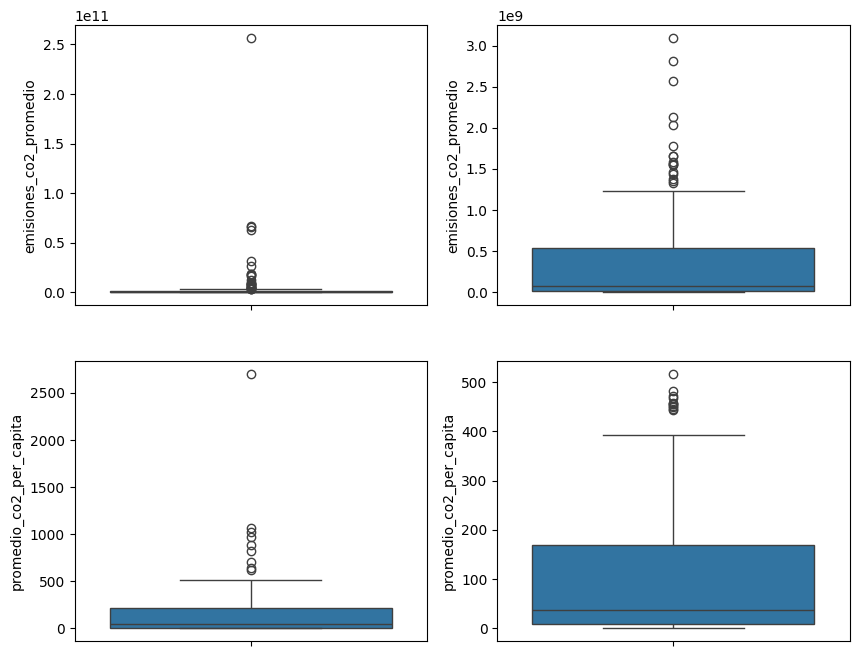

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
sns.boxplot(country_stats['emisiones_co2_promedio'], ax=axes[0, 0]);
sns.boxplot(country_stats['promedio_co2_per_capita'], ax=axes[1, 0]);
sns.boxplot(country_stats_filtrado_emisiones_promedio['emisiones_co2_promedio'], ax=axes[0, 1]);
sns.boxplot(country_stats_filtrado_promedio_emisiones_per_capita['promedio_co2_per_capita'], ax=axes[1, 1]);

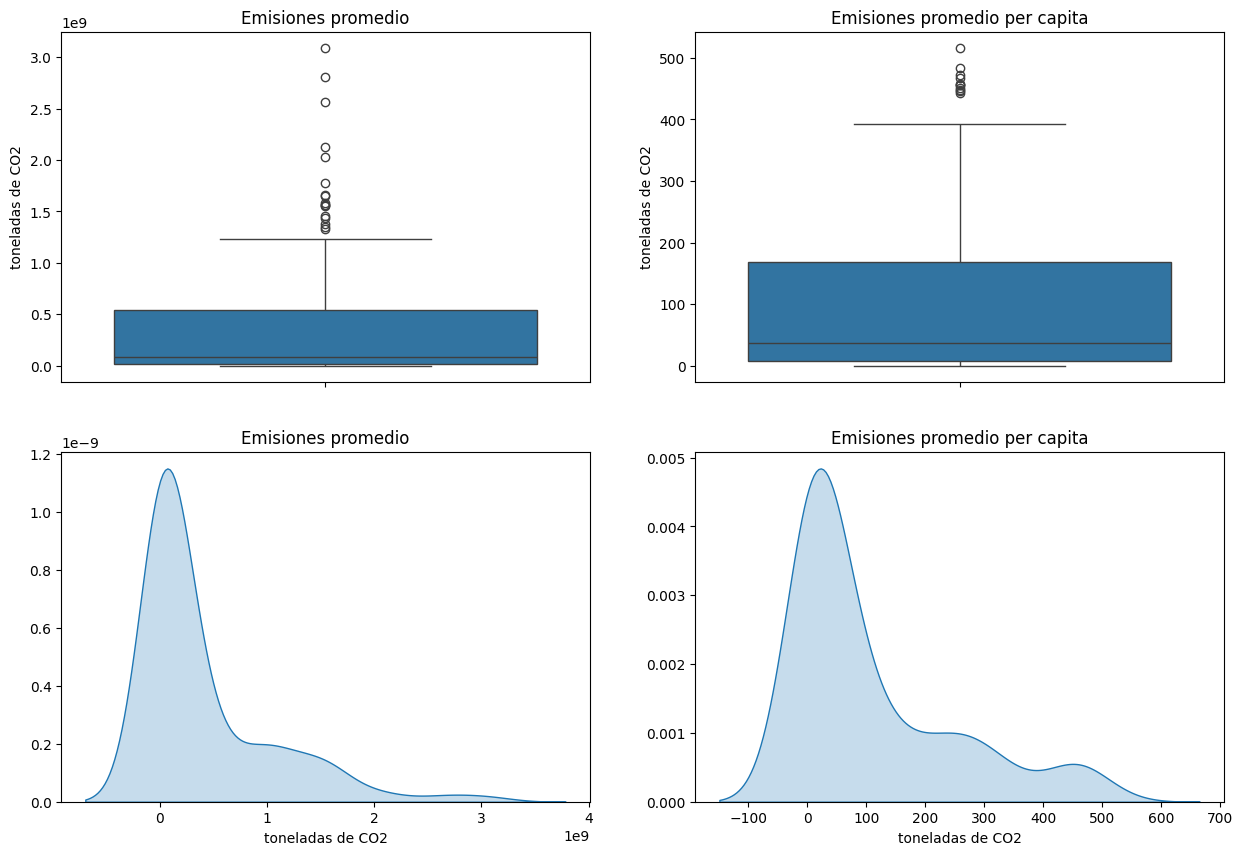

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.boxplot(country_stats_filtrado_emisiones_promedio['emisiones_co2_promedio'], ax=axes[0, 0]);
sns.boxplot(country_stats_filtrado_promedio_emisiones_per_capita['promedio_co2_per_capita'], ax=axes[0, 1]);
sns.kdeplot(country_stats_filtrado_emisiones_promedio['emisiones_co2_promedio'], fill=True, ax=axes[1, 0]);
sns.kdeplot(country_stats_filtrado_promedio_emisiones_per_capita['promedio_co2_per_capita'], fill=True, ax=axes[1, 1]);

axes[0, 0].set(title="Emisiones promedio", xlabel="", ylabel="toneladas de CO2")
axes[0, 1].set(title="Emisiones promedio per capita", xlabel="", ylabel="toneladas de CO2");
axes[1, 0].set(title="Emisiones promedio", xlabel="toneladas de CO2", ylabel="")
axes[1, 1].set(title="Emisiones promedio per capita", xlabel="toneladas de CO2", ylabel="");

## Analisis Poblacion

### Estimados de locacion

In [30]:
country_stats.sort_values(by='emisiones_co2_promedio', ascending=False).head()

,region,emisiones_co2_promedio,promedio_co2_per_capita,nivel_ingresos,agricultura,industria,servicios,poblacion_2020,tasa_de_crecimiento_poblacional,tasa_de_aumento_emisiones,country_code
pais,,,,,,,,,,,
United States,North America,2.565902e+11,973.872837,Alto,1.2,19.2,79.6,3.315011e+08,0.834833,2.504202,USA
China,East Asia & Pacific,6.730901e+10,53.308747,Medio alto,10.1,46.8,43.1,1.411100e+09,1.115370,45.263150,CHN
Germany,Europe & Central Asia,6.576388e+10,820.615230,Alto,0.8,28.6,70.6,8.316087e+07,0.142086,1.555079,DEU
United Kingdom,Europe & Central Asia,6.244003e+10,1062.129848,Alto,0.7,21.4,77.8,6.708100e+07,0.280172,0.747184,GBR
Japan,East Asia & Pacific,3.143629e+10,254.820980,Alto,1.2,27.3,71.6,1.262610e+08,0.354499,10.401149,JPN


In [31]:
country_stats.sort_values(by='emisiones_co2_promedio').head()

,region,emisiones_co2_promedio,promedio_co2_per_capita,nivel_ingresos,agricultura,industria,servicios,poblacion_2020,tasa_de_crecimiento_poblacional,tasa_de_aumento_emisiones,country_code
pais,,,,,,,,,,,
Tuvalu,East Asia & Pacific,73050.983607,7.003976,Medio alto,16.6,27.2,56.2,11069.0,1.048298,inf,TUV
Puerto Rico,Latin America & Caribbean,208848.000000,0.064548,Alto,1.0,45.0,54.0,3281538.0,0.391662,0.0,PRI
Turks and Caicos Islands,Latin America & Caribbean,717376.065574,22.921940,Alto,1.0,24.2,74.8,44276.0,6.900785,inf,TCA
Marshall Islands,East Asia & Pacific,746239.704918,14.908163,Medio alto,31.7,14.9,53.4,43413.0,1.823793,inf,MHL
Kiribati,East Asia & Pacific,796210.475410,8.717552,Medio bajo,8.9,24.2,66.8,126463.0,1.685388,inf,KIR


In [32]:
median = country_stats['emisiones_co2_promedio'].median()
country_stats[(country_stats['emisiones_co2_promedio'] > median - 5000000) & (country_stats['emisiones_co2_promedio'] < median + 5000000)]

,region,emisiones_co2_promedio,promedio_co2_per_capita,nivel_ingresos,agricultura,industria,servicios,poblacion_2020,tasa_de_crecimiento_poblacional,tasa_de_aumento_emisiones,country_code
pais,,,,,,,,,,,
Kenya,Sub-Saharan Africa,1.758323e+08,6.11357,Medio bajo,19.0,16.4,64.6,51985780.0,5.706601,21.994358,KEN
Sri Lanka,South Asia,1.670830e+08,8.99020,Medio bajo,13.0,29.6,57.4,21919000.0,1.219763,23.260002,LKA


In [33]:
countries_path = '/content/drive/MyDrive/Colab Notebooks/proyecto_bedu_modulo_3/countries.geo.json'

m = folium.Map(location=[30, 0], zoom_start=2, width="80%", height="90%")

folium.Choropleth(
    geo_data=countries_path,
    name="choropleth",
    data=country_stats,
    columns=["country_code", "emisiones_co2_promedio"],
    key_on="feature.id",
    fill_color="YlGn",
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name="Emisiones de CO2 (ton)"
).add_to(m)

folium.LayerControl().add_to(m)
m
# rusia, istambul, nigeria, venezuela

In [34]:
emissions_classified = emissions_populations_incomes_activities.groupby(['pais', 'año']).agg(
    emisiones_co2=('toneladas_co2_emitidas', 'first'),
    emisiones_co2_per_capita=('toneladas_co2_per_capita', 'first'),
    poblacion=('poblacion', 'first'),
    nivel_ingresos=('nivel_ingresos', lambda x: nivel_ingresos_mapping[x.iloc[0]])
)

emissions_classified.head()

emisiones_co2  emisiones_co2_per_capita  poblacion  \
pais        año                                                        
Afghanistan 1960      2253064.0                  0.261302  8622466.0   
            1961      2743862.0                  0.312152  8790140.0   
            1962      3432456.0                  0.382700  8969047.0   
            1963      4139192.0                  0.452002  9157465.0   
            1964      4977743.0                  0.532065  9355514.0   

                  nivel_ingresos  
pais        año                   
Afghanistan 1960               0  
            1961               0  
            1962               0  
            1963               0  
            1964               0

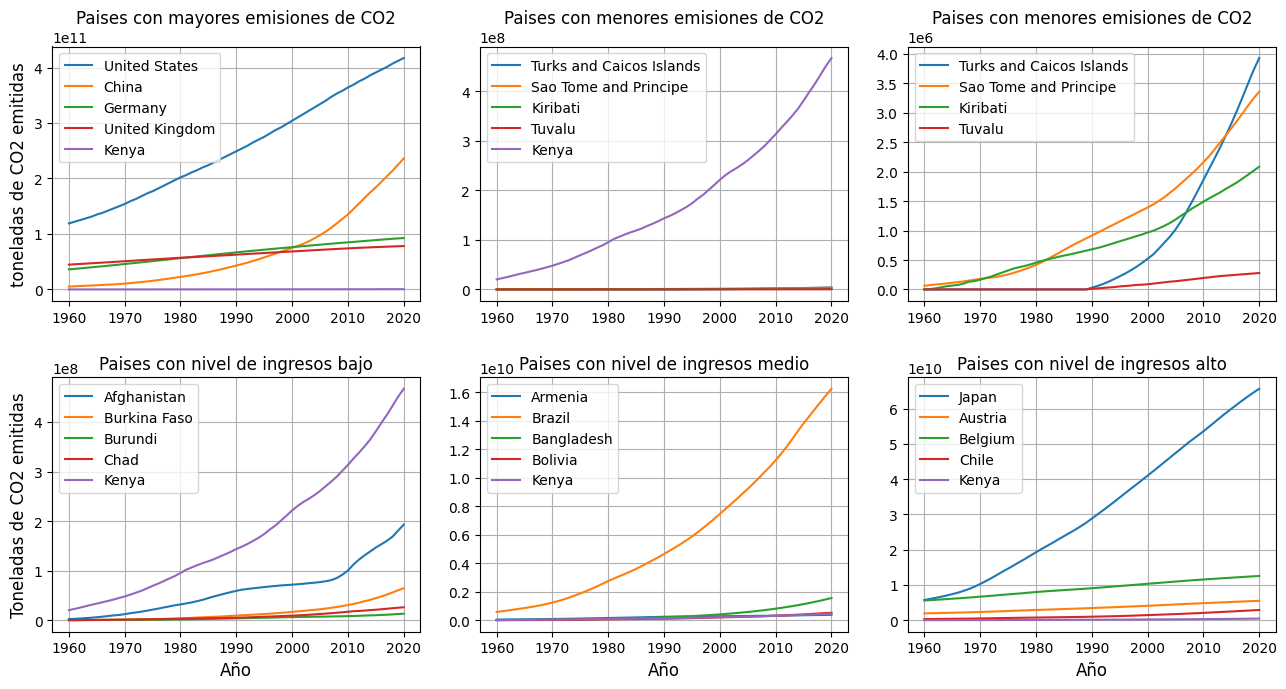

In [35]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7))

def plot_emissions_over_time(x, y, title, paises_interes):
  df_filtrado = emissions_classified.loc[paises_interes].reset_index()
  for pais in paises_interes:
    pais_data = df_filtrado[df_filtrado['pais'] == pais]
    axs[x, y].plot(pais_data['año'], pais_data['emisiones_co2'], label=pais)

  axs[x, y].set_title(title)
  axs[x, y].legend()
  axs[x, y].grid(True)

plot_emissions_over_time(0, 0, 'Paises con mayores emisiones de CO2', ['United States', 'China', 'Germany', 'United Kingdom', 'Kenya'])
plot_emissions_over_time(0, 1, 'Paises con menores emisiones de CO2', ['Turks and Caicos Islands', 'Sao Tome and Principe', 'Kiribati', 'Tuvalu', 'Kenya'])
plot_emissions_over_time(0, 2, 'Paises con menores emisiones de CO2', ['Turks and Caicos Islands', 'Sao Tome and Principe', 'Kiribati', 'Tuvalu'])
plot_emissions_over_time(1, 0, 'Paises con nivel de ingresos bajo', ['Afghanistan', 'Burkina Faso', 'Burundi', 'Chad', 'Kenya'])
plot_emissions_over_time(1, 1, 'Paises con nivel de ingresos medio', ['Armenia', 'Brazil', 'Bangladesh', 'Bolivia', 'Kenya'])
plot_emissions_over_time(1, 2, 'Paises con nivel de ingresos alto', ['Japan', 'Austria', 'Belgium', 'Chile', 'Kenya'])

axs[0, 0].set_ylabel("toneladas de CO2 emitidas", fontsize=12)

axs[1, 0].set_xlabel("Año", fontsize=12)
axs[1, 0].set_ylabel("Toneladas de CO2 emitidas", fontsize=12)

axs[1, 1].set_xlabel("Año", fontsize=12)

axs[1, 2].set_xlabel("Año", fontsize=12)

plt.tight_layout()
plt.show()


### Poblacion y emisiones

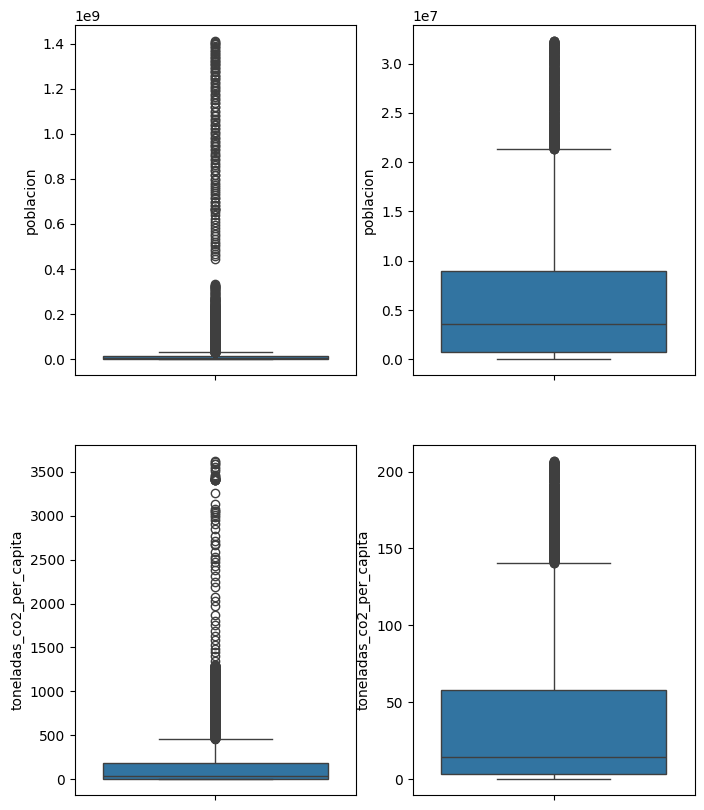

In [36]:
fig, axs = plt.subplots(2, 2, figsize=(8, 10))

iqr_poblacion = emissions_populations_incomes_activities['poblacion'].quantile(0.75) - emissions_populations_incomes_activities['poblacion'].quantile(0.25)

filtro_superior = emissions_populations_incomes_activities['poblacion'] > emissions_populations_incomes_activities['poblacion'].quantile(0.25) - 1.5 * iqr_poblacion
filtro_inferior = emissions_populations_incomes_activities['poblacion'] < emissions_populations_incomes_activities['poblacion'].quantile(0.75) + 1.5 * iqr_poblacion

poblacion_filtrado = emissions_populations_incomes_activities[filtro_superior & filtro_inferior]

sns.boxplot(emissions_populations_incomes_activities['poblacion'], ax=axs[0, 0])
sns.boxplot(poblacion_filtrado['poblacion'], ax=axs[0, 1]);

iqr_emisiones = emissions_populations_incomes_activities['toneladas_co2_per_capita'].quantile(0.75) - emissions_populations_incomes_activities['toneladas_co2_per_capita'].quantile(0.25)

filtro_superior = emissions_populations_incomes_activities['toneladas_co2_per_capita'] > emissions_populations_incomes_activities['toneladas_co2_per_capita'].quantile(0.25) - 0.1 * iqr_emisiones
filtro_inferior = emissions_populations_incomes_activities['toneladas_co2_per_capita'] < emissions_populations_incomes_activities['toneladas_co2_per_capita'].quantile(0.75) + 0.1 * iqr_emisiones

emisiones_filtrado = emissions_populations_incomes_activities[filtro_superior & filtro_inferior]

sns.boxplot(emissions_populations_incomes_activities['toneladas_co2_per_capita'], ax=axs[1, 0])
sns.boxplot(emisiones_filtrado['toneladas_co2_per_capita'], ax=axs[1, 1]);

Coeficiente de correlacion de pearson entre emisiones per capita y poblacion:  -0.009316000198759953


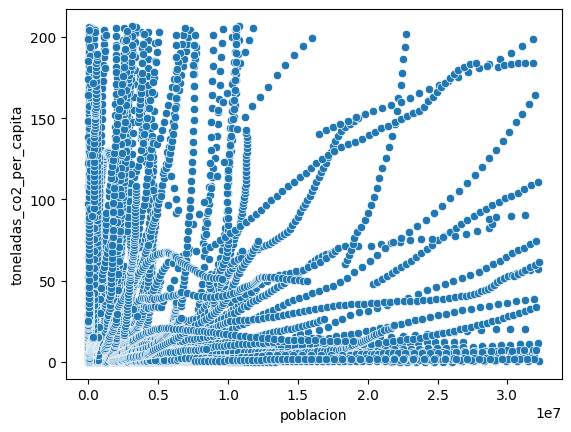

In [37]:
df = poblacion_filtrado.merge(emisiones_filtrado, how='inner', copy=False)
print('Coeficiente de correlacion de pearson entre emisiones per capita y poblacion: ', df['poblacion'].corr(df['toneladas_co2_per_capita']))
sns.scatterplot(df, x='poblacion', y='toneladas_co2_per_capita');

### Poblaciones y actividad economica

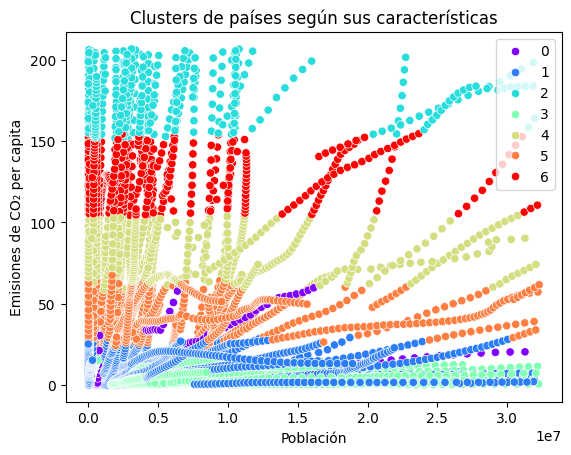

In [38]:
k_means = KMeans(n_clusters=7, max_iter=10000)
k_means.fit(df[[ '%_empleo_agricultura', '%_empleo_industria', '%_empleo_servicios', 'toneladas_co2_per_capita']])
clasificaciones = k_means.predict(df[['%_empleo_agricultura', '%_empleo_industria', '%_empleo_servicios', 'toneladas_co2_per_capita']])

fig = plt.figure()

sns.scatterplot(x=df['poblacion'], y=df['toneladas_co2_per_capita'], hue=clasificaciones, palette='rainbow');

plt.xlabel('Población')
plt.ylabel('Emisiones de CO₂ per capita')
plt.title('Clusters de países según sus características')
plt.show()

In [39]:
df['clasificacion'] = clasificaciones

In [40]:
analisis_poblaciones = df.groupby('clasificacion').agg(
    sector_agricultura=('%_empleo_agricultura', 'mean'),
    sector_industria=('%_empleo_industria', 'mean'),
    sector_servicios=('%_empleo_servicios', 'mean'),
    poblacion_promedio=('poblacion', 'mean'),
    emisiones_promedio=('toneladas_co2_emitidas', 'mean')
)
analisis_poblaciones

,sector_agricultura,sector_industria,sector_servicios,poblacion_promedio,emisiones_promedio
clasificacion,,,,,
0,10.188759,60.211944,29.195785,4.073480e+06,7.011311e+07
1,12.463091,26.513598,61.017610,4.945899e+06,5.023985e+07
2,5.670327,29.142757,65.074533,6.074738e+06,1.081026e+09
3,39.814801,17.669820,42.994273,8.577970e+06,3.124545e+07
4,8.367115,30.207773,61.367862,6.470911e+06,5.148499e+08
5,9.105321,24.901376,65.964495,5.898745e+06,2.574342e+08
6,6.825376,31.552632,61.558647,5.464534e+06,7.063758e+08


In [41]:
analisis_poblaciones['empleados_agricultura'] = analisis_poblaciones['poblacion_promedio'] * analisis_poblaciones['sector_agricultura']
analisis_poblaciones['empleados_industria'] = analisis_poblaciones['poblacion_promedio'] * analisis_poblaciones['sector_industria']
analisis_poblaciones['empleados_servicios'] = analisis_poblaciones['poblacion_promedio'] * analisis_poblaciones['sector_servicios']
analisis_poblaciones

,sector_agricultura,sector_industria,sector_servicios,poblacion_promedio,emisiones_promedio,empleados_agricultura,empleados_industria,empleados_servicios
clasificacion,,,,,,,,
0,10.188759,60.211944,29.195785,4.073480e+06,7.011311e+07,4.150370e+07,2.452721e+08,1.189284e+08
1,12.463091,26.513598,61.017610,4.945899e+06,5.023985e+07,6.164119e+07,1.311336e+08,3.017869e+08
2,5.670327,29.142757,65.074533,6.074738e+06,1.081026e+09,3.444575e+07,1.770346e+08,3.953108e+08
3,39.814801,17.669820,42.994273,8.577970e+06,3.124545e+07,3.415302e+08,1.515712e+08,3.688036e+08
4,8.367115,30.207773,61.367862,6.470911e+06,5.148499e+08,5.414286e+07,1.954718e+08,3.971060e+08
5,9.105321,24.901376,65.964495,5.898745e+06,2.574342e+08,5.370997e+07,1.468869e+08,3.891077e+08
6,6.825376,31.552632,61.558647,5.464534e+06,7.063758e+08,3.729750e+07,1.724204e+08,3.363893e+08


In [42]:
X = df[['%_empleo_agricultura', '%_empleo_industria', '%_empleo_servicios']] # independientes
y = df['toneladas_co2_per_capita'] # dependiente

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = LinearRegression()
model.fit(X_train, y_train)

model.score(X_test, y_test)

0.17583855612344723

In [43]:
scores = cross_validate(model, X, y, scoring='r2')

print(f'Score del modelo: {scores["test_score"].mean():.3f} +/- {scores["test_score"].std():.3f}')

Score del modelo: 0.098 +/- 0.173


### Crecimiento poblacional y aumento de emisiones

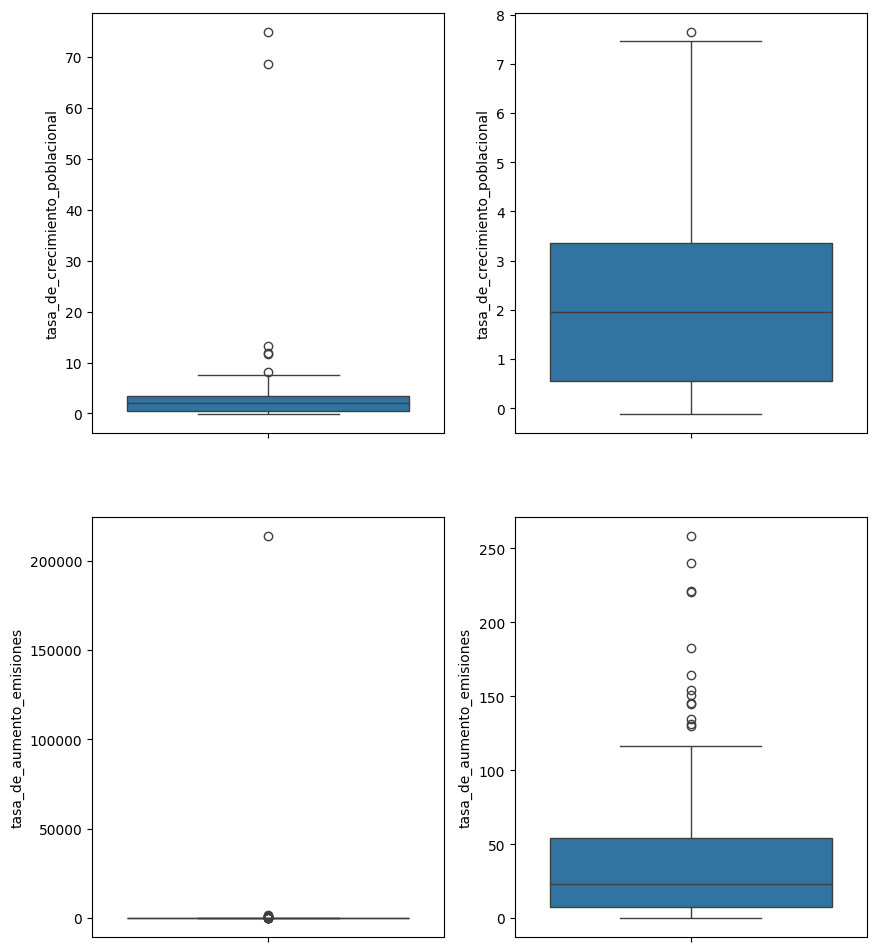

In [44]:
fig, axs = plt.subplots(2, 2, figsize=(10, 12))

iqr_poblacion = country_stats['tasa_de_crecimiento_poblacional'].quantile(0.75) - country_stats['tasa_de_crecimiento_poblacional'].quantile(0.25)
iqr_emisiones = country_stats['tasa_de_aumento_emisiones'].quantile(0.75) - country_stats['tasa_de_aumento_emisiones'].quantile(0.25)

filtro_superior_poblacion = country_stats['tasa_de_crecimiento_poblacional'] > country_stats['tasa_de_crecimiento_poblacional'].quantile(0.25) - 1.5 * iqr_poblacion
filtro_inferior_poblacion = country_stats['tasa_de_crecimiento_poblacional'] < country_stats['tasa_de_crecimiento_poblacional'].quantile(0.75) + 1.5 * iqr_poblacion

filtro_superior_emisiones = country_stats['tasa_de_aumento_emisiones'] > country_stats['tasa_de_aumento_emisiones'].quantile(0.25) - 1.5 * iqr_emisiones
filtro_inferior_emisiones = country_stats['tasa_de_aumento_emisiones'] < country_stats['tasa_de_aumento_emisiones'].quantile(0.75) + 1.5 * iqr_emisiones

country_stats_filtrado_crecimiento_poblacion = country_stats[filtro_superior_poblacion & filtro_inferior_poblacion]
country_stats_filtrado_aumento_emisiones = country_stats[filtro_superior_emisiones & filtro_inferior_emisiones]

sns.boxplot(country_stats['tasa_de_crecimiento_poblacional'], ax=axs[0, 0])
sns.boxplot(country_stats_filtrado_crecimiento_poblacion['tasa_de_crecimiento_poblacional'], ax=axs[0, 1]);
sns.boxplot(country_stats['tasa_de_aumento_emisiones'], ax=axs[1, 0])
sns.boxplot(country_stats_filtrado_aumento_emisiones['tasa_de_aumento_emisiones'], ax=axs[1, 1]);

Coeficiente de correlacion de pearson entre el aumento de emisiones y el crecimiento poblacional:  0.48358657719806536


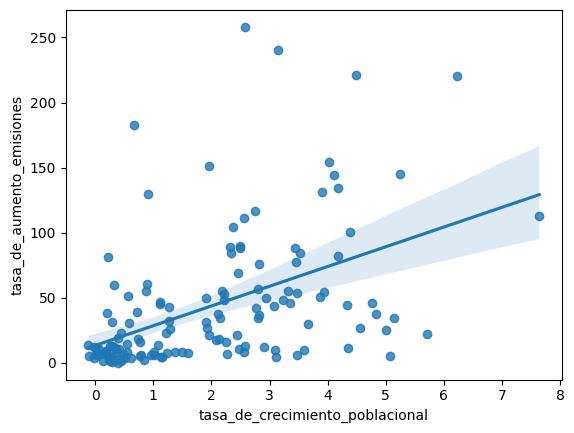

In [45]:
df = country_stats_filtrado_crecimiento_poblacion.merge(country_stats_filtrado_aumento_emisiones, how='inner', copy=False)
print('Coeficiente de correlacion de pearson entre el aumento de emisiones y el crecimiento poblacional: ', df['tasa_de_crecimiento_poblacional'].corr(df['tasa_de_aumento_emisiones']))
sns.regplot(df, x='tasa_de_crecimiento_poblacional', y='tasa_de_aumento_emisiones');

In [46]:
lr = LinearRegression()
lr.fit(df[['tasa_de_crecimiento_poblacional']], df['tasa_de_aumento_emisiones'])

LinearRegression()

In [47]:
lr.score(df[['tasa_de_crecimiento_poblacional']], df['tasa_de_aumento_emisiones'])

0.2338559776461403

## Analisis Nivel de Ingresos

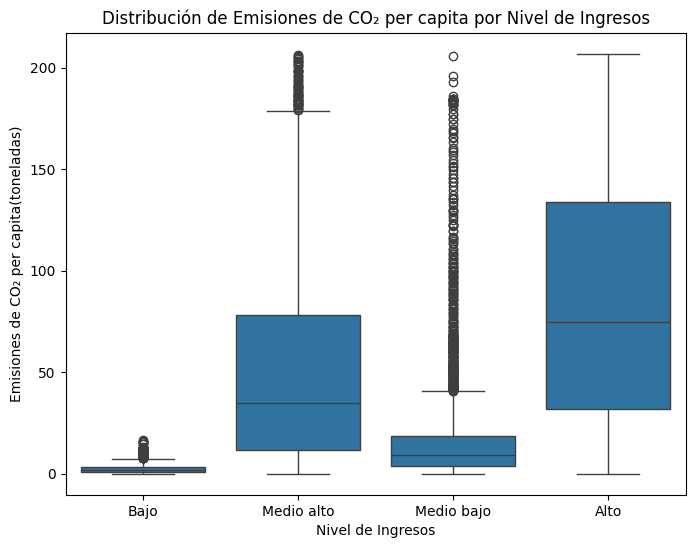

In [48]:
plt.figure(figsize=(8,6))
sns.boxplot(data=emisiones_filtrado, x='nivel_ingresos', y='toneladas_co2_per_capita')
plt.title('Distribución de Emisiones de CO₂ per capita por Nivel de Ingresos')
plt.ylabel('Emisiones de CO₂ per capita(toneladas)')
plt.xlabel('Nivel de Ingresos')
plt.show();

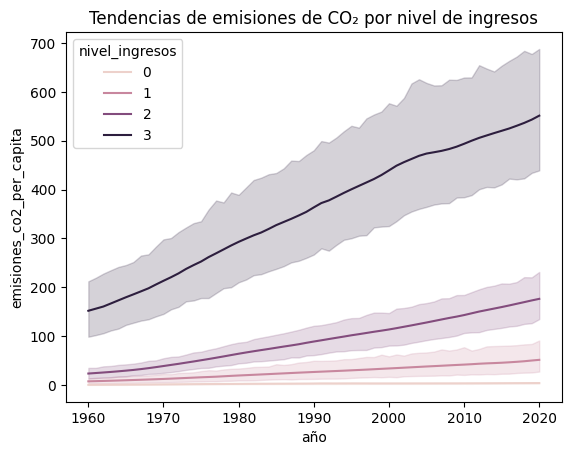

In [49]:
sns.lineplot(data=emissions_classified, x='año', y='emisiones_co2_per_capita', hue='nivel_ingresos')
plt.title('Tendencias de emisiones de CO₂ por nivel de ingresos')
plt.show()

In [50]:
grupo_alto = emisiones_filtrado[emisiones_filtrado['nivel_ingresos'] == 'Alto']['toneladas_co2_emitidas']
grupo_medio_alto = emisiones_filtrado[emisiones_filtrado['nivel_ingresos'] == 'Medio alto']['toneladas_co2_emitidas']
grupo_medio_bajo = emisiones_filtrado[emisiones_filtrado['nivel_ingresos'] == 'Medio bajo']['toneladas_co2_emitidas']
grupo_bajo = emisiones_filtrado[emisiones_filtrado['nivel_ingresos'] == 'Bajo']['toneladas_co2_emitidas']

anova_result = f_oneway(grupo_alto, grupo_bajo)
print(f'Valor de p del ANOVA (Alta-Baja): {anova_result.pvalue}')

anova_result = f_oneway(grupo_alto, grupo_medio_alto)
print(f'Valor de p del ANOVA (Alta-Medio Alto): {anova_result.pvalue}')

anova_result = f_oneway(grupo_medio_alto, grupo_medio_bajo)
print(f'Valor de p del ANOVA (Medio Alta-Medio Bajo): {anova_result.pvalue}')

anova_result = f_oneway(grupo_bajo, grupo_medio_bajo)
print(f'Valor de p del ANOVA (Bajo-Medio Bajo): {anova_result.pvalue}')

Valor de p del ANOVA (Alta-Baja): 1.0967289204140527e-28
Valor de p del ANOVA (Alta-Medio Alto): 2.3854738481869324e-06
Valor de p del ANOVA (Medio Alta-Medio Bajo): 7.351005789964816e-10
Valor de p del ANOVA (Bajo-Medio Bajo): 1.2589846406587116e-12
